In [ ]:
import pandas as pd
data=pd.read_csv("loan-train.csv")
print(data)

      Loan_ID  Gender Married Dependents     Education Self_Employed  \
0    LP001002    Male      No          0      Graduate            No   
1    LP001003    Male     Yes          1      Graduate            No   
2    LP001005    Male     Yes          0      Graduate           Yes   
3    LP001006    Male     Yes          0  Not Graduate            No   
4    LP001008    Male      No          0      Graduate            No   
..        ...     ...     ...        ...           ...           ...   
609  LP002978  Female      No          0      Graduate            No   
610  LP002979    Male     Yes         3+      Graduate            No   
611  LP002983    Male     Yes          1      Graduate            No   
612  LP002984    Male     Yes          2      Graduate            No   
613  LP002990  Female      No          0      Graduate           Yes   

     ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0               5849                0.0         NaN           

In [ ]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [ ]:
data.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [ ]:
data['Gender']=data['Gender'].fillna(0)
data['Married']=data['Married'].fillna(0)
data['Dependents']=data['Dependents'].fillna(0)
data['Self_Employed']=data['Self_Employed'].fillna(0)
data['LoanAmount']=data['LoanAmount'].fillna(0)
data['Loan_Amount_Term']=data['Loan_Amount_Term'].fillna(0)
data['Credit_History']=data['Credit_History'].fillna(0)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             614 non-null    object 
 2   Married            614 non-null    object 
 3   Dependents         614 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      614 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    float64
 10  Credit_History     614 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

# Convert columns that might have mixed int/str types to string before encoding
data['Gender'] = data['Gender'].astype(str)
data['Married'] = data['Married'].astype(str)
data['Dependents'] = data['Dependents'].astype(str)
data['Self_Employed'] = data['Self_Employed'].astype(str)

data['Gender']=le.fit_transform(data['Gender'])
data['Loan_ID']=le.fit_transform(data['Loan_ID'])
data['Married']=le.fit_transform(data['Married'])
data['Dependents']=le.fit_transform(data['Dependents'])
data['Education']=le.fit_transform(data['Education'])
data['Self_Employed']=le.fit_transform(data['Self_Employed'])
data['Property_Area']=le.fit_transform(data['Property_Area'])
data['Loan_Status']=le.fit_transform(data['Loan_Status'])

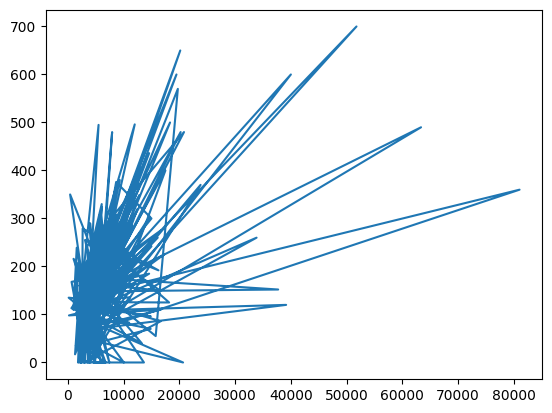

In [ ]:
from matplotlib import pyplot as plt
plt.plot(data['ApplicantIncome'],data['LoanAmount'])
plt.show()

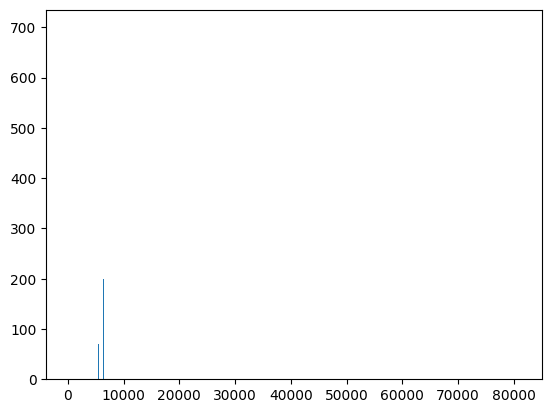

In [ ]:
from matplotlib import pyplot as plt
plt.bar(data['ApplicantIncome'],data['LoanAmount'])
plt.show()

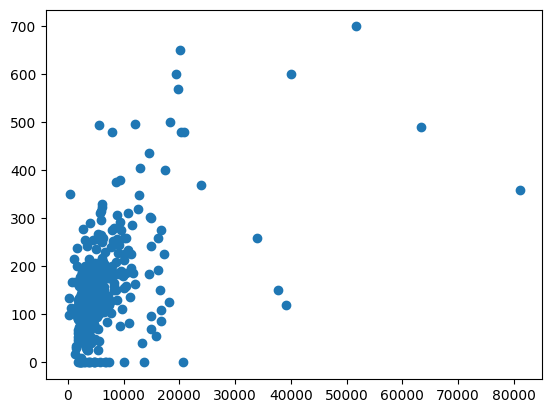

In [ ]:
from matplotlib import pyplot as plt
plt.scatter(data['ApplicantIncome'],data['LoanAmount'])
plt.show()

<Axes: xlabel='ApplicantIncome', ylabel='LoanAmount'>

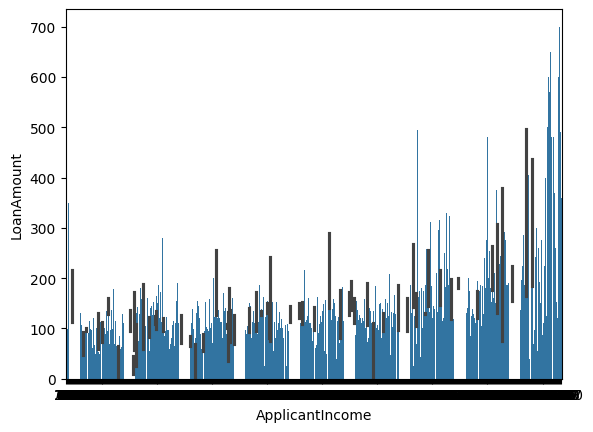

In [ ]:
import seaborn as s
s.barplot(x='ApplicantIncome',y='LoanAmount',data=data)


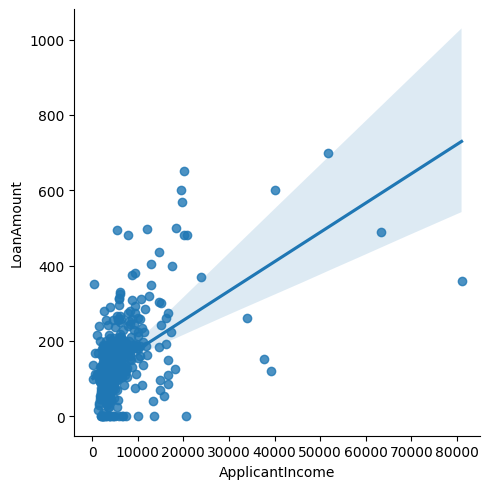

In [ ]:
import seaborn as s
s.lmplot(x='ApplicantIncome',y='LoanAmount',data=data)

<Axes: xlabel='Credit_History', ylabel='LoanAmount'>

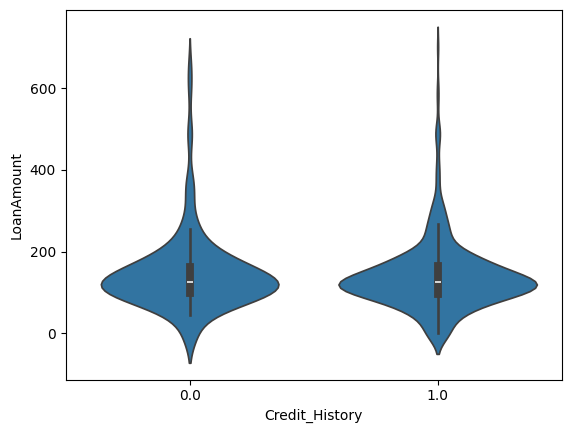

In [ ]:
import seaborn as s
s.violinplot(x='Credit_History',y='LoanAmount',data=data)

/tmp/ipykernel_1840/1284774342.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  s.distplot(data)


<Axes: ylabel='Density'>

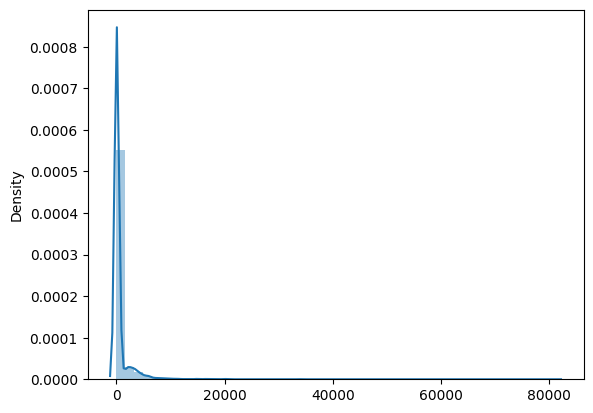

In [ ]:
import seaborn as s
s.distplot(data)

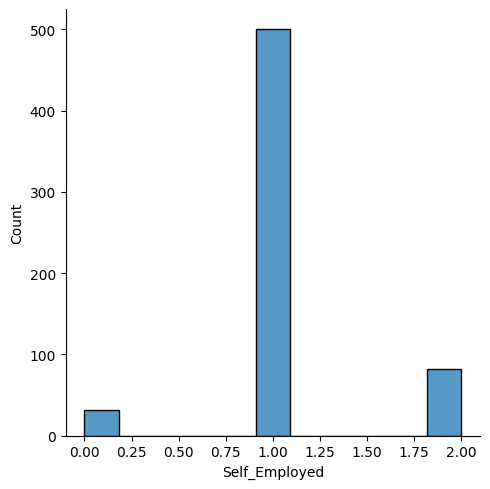

In [ ]:
import seaborn as s
s.displot(data['Self_Employed'])

<Axes: ylabel='Density'>

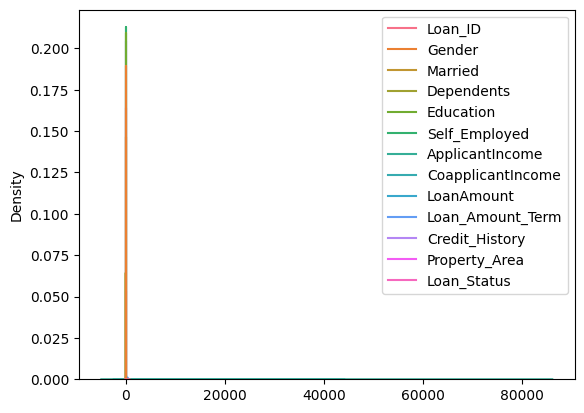

In [ ]:
import seaborn as s
s.kdeplot(x=data['LoanAmount'])

<Axes: ylabel='count'>

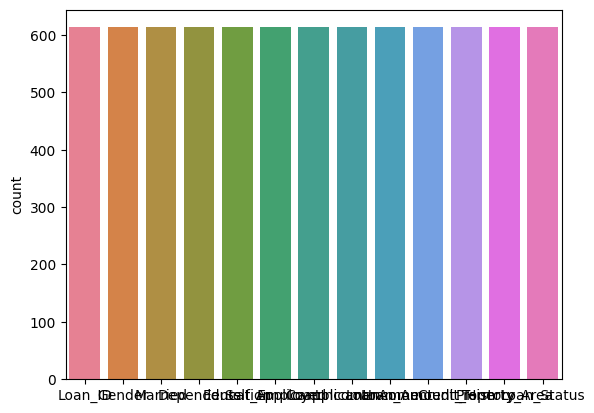

In [ ]:
import seaborn as s
s.countplot(x=data['Loan_Status'])

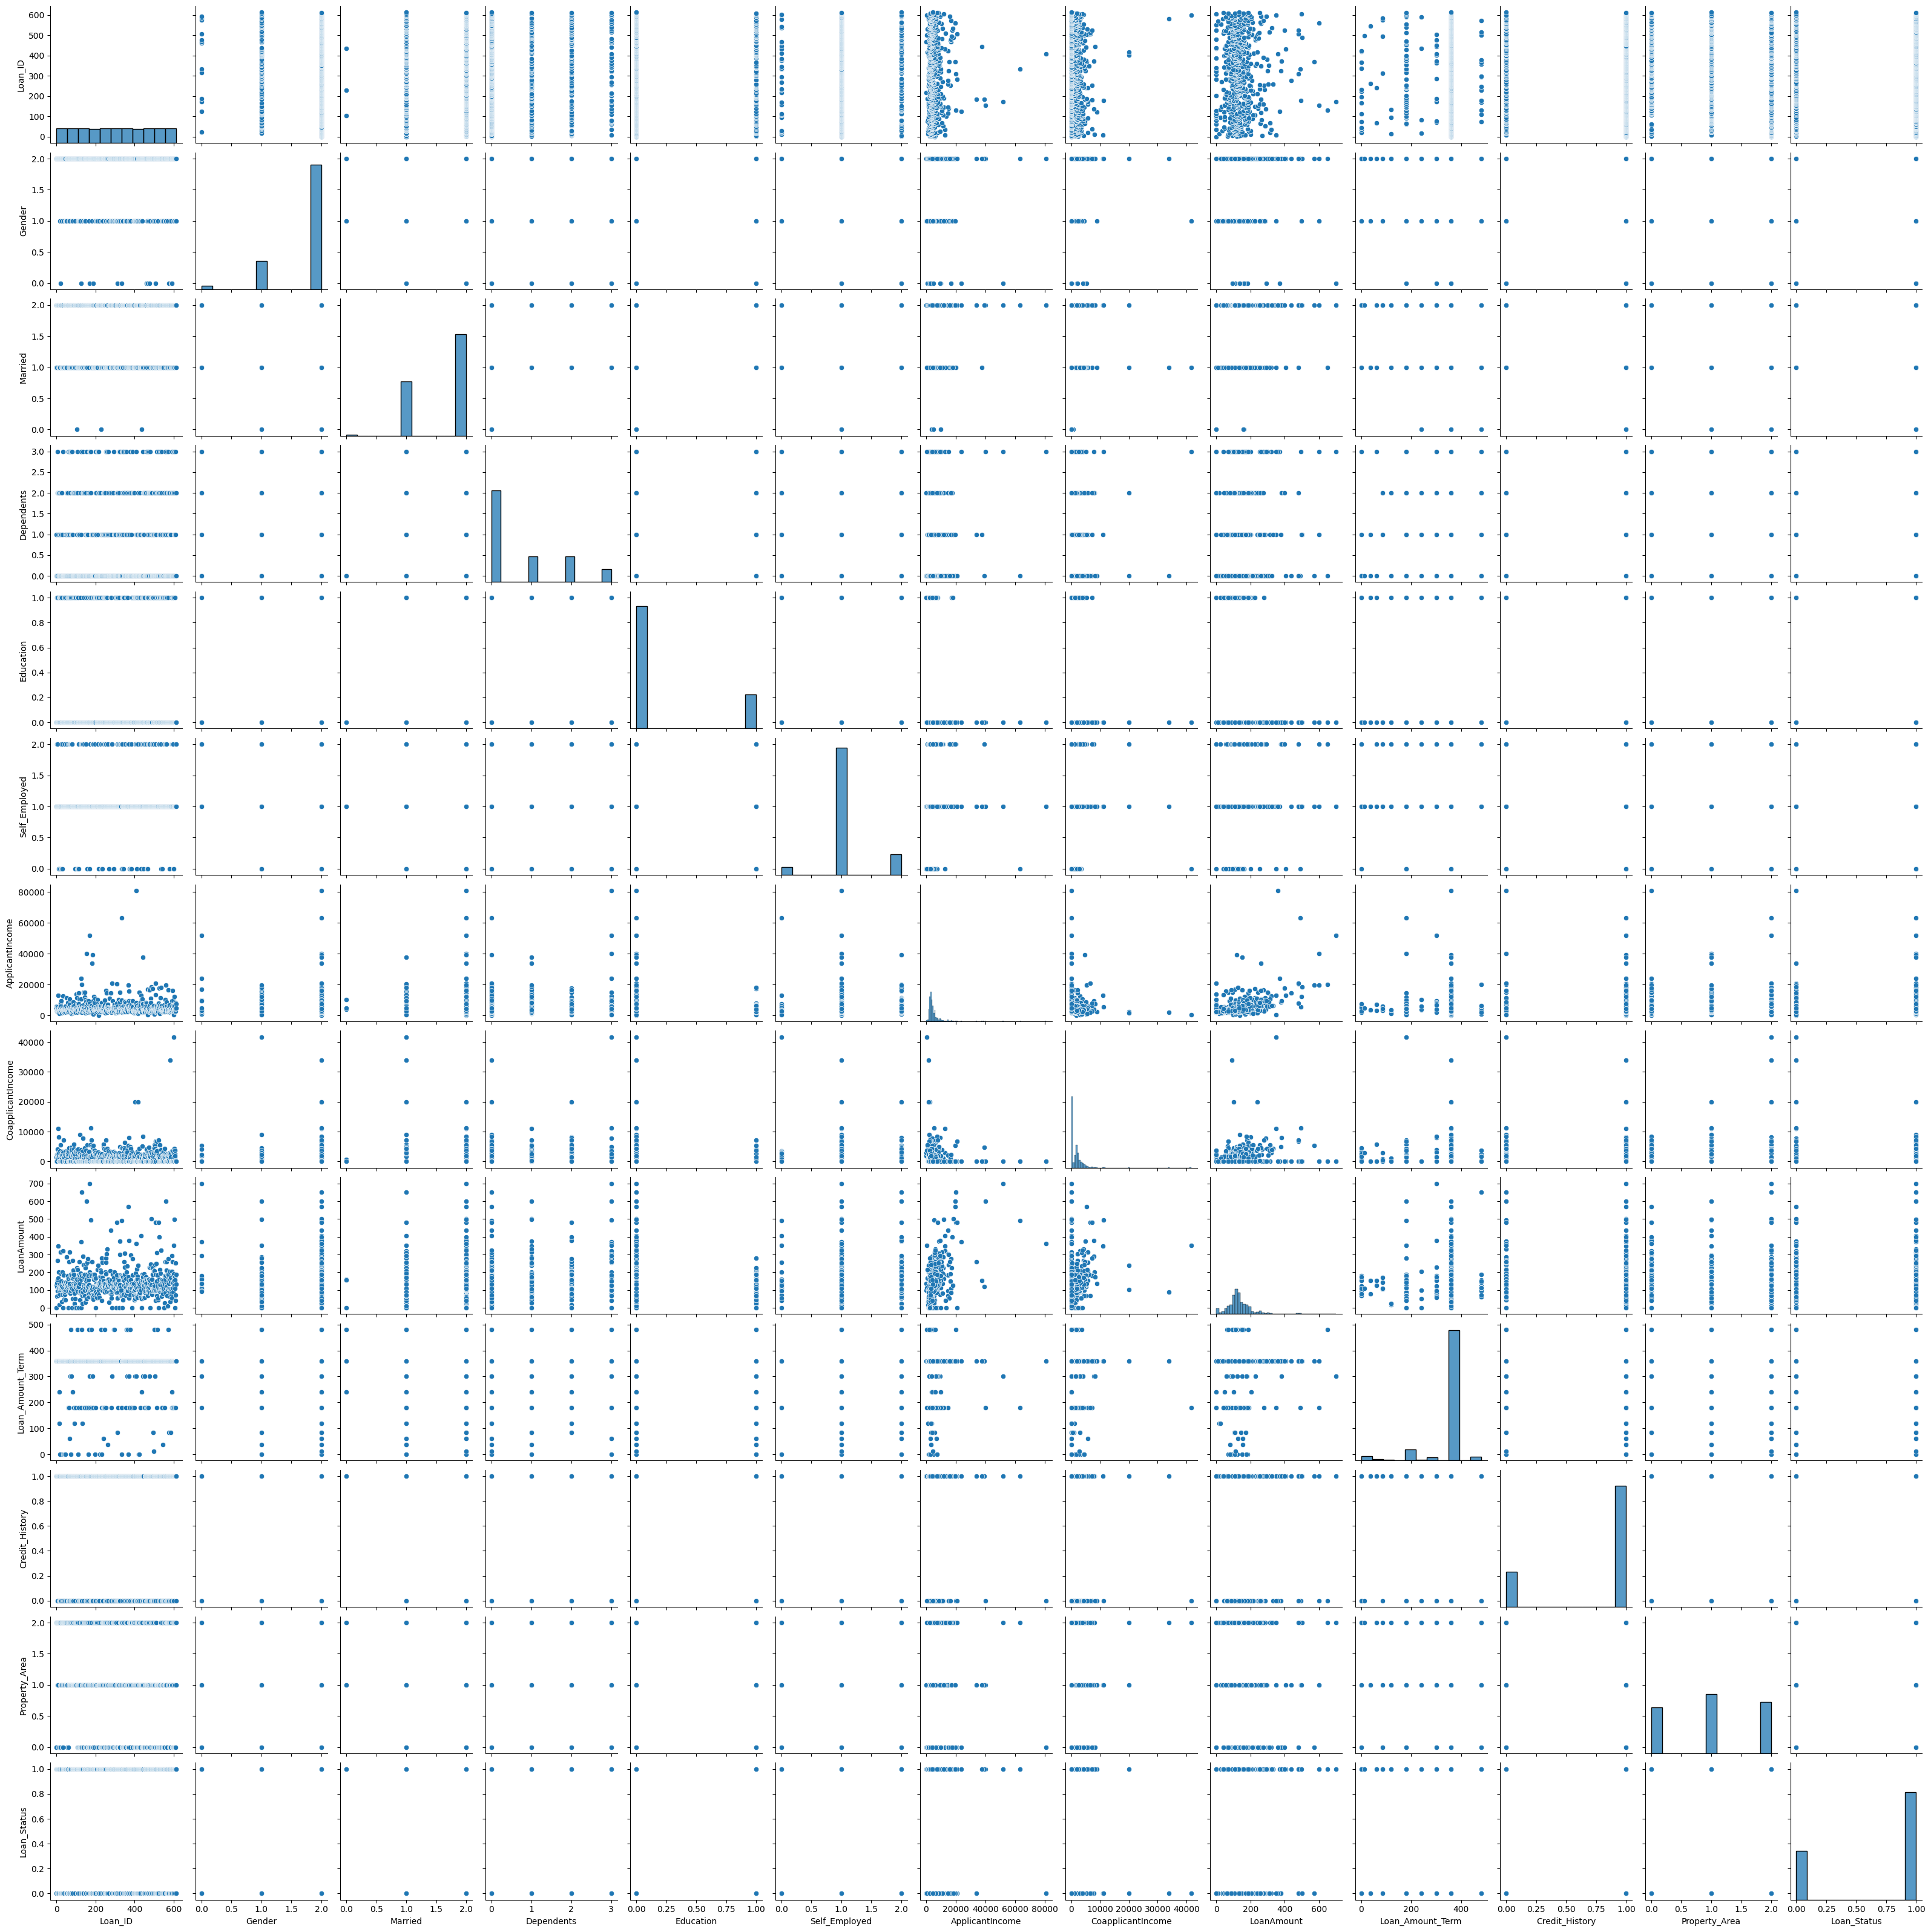

In [ ]:
import seaborn as s
s.pairplot(data)

<Axes: >

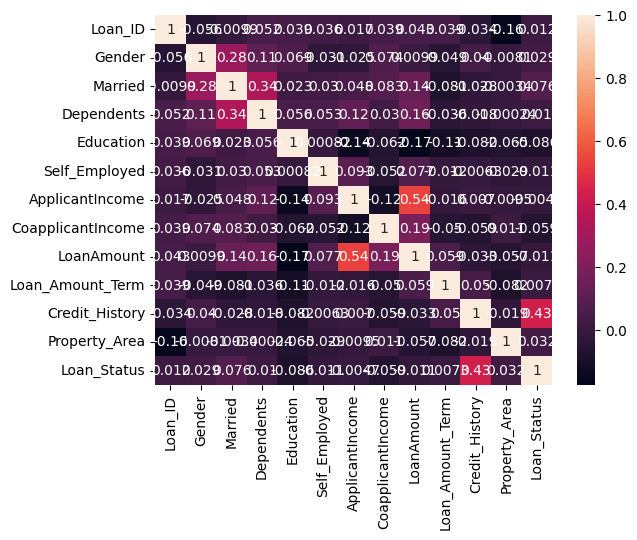

In [ ]:
a=data.corr(numeric_only=True)
s.heatmap(a,annot=True)


In [ ]:
x=data.drop('Loan_Status',axis=1)
y=data['Loan_Status']
print(x)
print(y)

     Loan_ID  Gender  Married  Dependents  Education  Self_Employed  \
0          0       2        1           0          0              1   
1          1       2        2           1          0              1   
2          2       2        2           0          0              2   
3          3       2        2           0          1              1   
4          4       2        1           0          0              1   
..       ...     ...      ...         ...        ...            ...   
609      609       1        1           0          0              1   
610      610       2        2           3          0              1   
611      611       2        2           1          0              1   
612      612       2        2           2          0              1   
613      613       1        1           0          0              2   

     ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0               5849                0.0         0.0             360.0   
1

In [ ]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x, y, test_size=0.2, random_state=42)
print(xtrain)
print(xtest)
print(ytrain)
print(ytest)

     Loan_ID  Gender  Married  Dependents  Education  Self_Employed  \
140      140       2        2           2          0              1   
399      399       1        1           0          0              1   
340      340       2        2           3          1              1   
218      218       2        2           2          0              0   
506      506       2        2           0          0              1   
..       ...     ...      ...         ...        ...            ...   
475      475       2        2           2          0              2   
35        35       2        2           0          0              1   
323      323       1        1           0          0              1   
283      283       1        1           0          0              1   
193      193       2        1           0          0              1   

     ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
140             5042             2083.0       185.0             360.0   
3

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model=RandomForestClassifier()
model.fit(xtrain,ytrain)

RandomForestClassifier()

In [ ]:
ypred=model.predict(xtest)

In [ ]:
from sklearn.metrics import accuracy_score
print(accuracy_score(ytest,ypred))


0.7723577235772358


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(ytest,ypred))


              precision    recall  f1-score   support

           0       0.55      0.52      0.53        31
           1       0.84      0.86      0.85        92

    accuracy                           0.77       123
   macro avg       0.70      0.69      0.69       123
weighted avg       0.77      0.77      0.77       123



In [ ]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(ytest,ypred))


[[16 15]
 [13 79]]


In [ ]:
ypred=model.predict([[506,2,2,0,0,1,20833,6667.0,480.0,360.0,0.0,2]])
print (ypred)

[1]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


### Notes
- This notebook keeps the original workflow, algorithms, and analysis style.
- Dataset files are not included; place the required CSV file in the notebook's working directory before running.
- Small compatibility and correctness fixes have been applied where needed.